# 06 · ReLU Networks from Scratch: Piecewise-Linear Functions, Universal Approximation, Bias vs Variance

**Thesis reference:** Chapter 2: 2.0.2 *Bias vs Variance*, 2.1 *The Construction of Deep Neural Networks* (2.1.1 $F_k$ is piecewise linear, 2.1.7–2.1.9 counting flat pieces and composition, 2.1.10 universal approximation).

A neural network with ReLU activations computes
$$F(v) = A_L\,\mathrm{ReLU}\big(A_{L-1} \cdots \mathrm{ReLU}(A_1 v + b_1) \cdots + b_{L-1}\big) + b_L,$$
a **continuous piecewise-linear** function of the input $v$. Everything here is implemented in plain NumPy, with backpropagation written out by hand.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb
from pathlib import Path

FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
relu = lambda z: np.maximum(z, 0)

## 1. Counting linear pieces: one hidden layer

With input $v \in \mathbb{R}^m$ and $N$ hidden ReLU neurons, each neuron switches on or off across a hyperplane $w_i^Tv + b_i = 0$.
$N$ hyperplanes in general position cut $\mathbb{R}^m$ into
$$r(N, m) = \sum_{i=0}^{m} \binom{N}{i}$$
regions, and $F$ is linear on each one. We check the formula for $m = 2$ by sampling a fine grid and counting distinct on/off **activation patterns**.

In [2]:
rng = np.random.default_rng(0)

def count_regions_2d(N, grid=1200, seed=0):
    r = np.random.default_rng(seed)
    W, b = r.standard_normal((N, 2)), r.standard_normal(N)
    # box large enough to contain every line and every pairwise intersection of the N lines
    extent = list(np.abs(b) / np.linalg.norm(W, axis=1))
    for i in range(N):
        for j in range(i + 1, N):
            M = np.array([W[i], W[j]])
            if abs(np.linalg.det(M)) > 1e-9:
                extent.append(np.abs(np.linalg.solve(M, -np.array([b[i], b[j]]))).max())
    L = 1.2 * max(extent) + 1
    g = np.linspace(-L, L, grid)
    V = np.stack(np.meshgrid(g, g), -1).reshape(-1, 2)
    patterns = (V @ W.T + b > 0)
    codes = np.packbits(patterns, axis=1)
    return len(np.unique(codes, axis=0)), patterns, g, W, b

print(f"{'N neurons':>9s} {'formula r(N,2)':>15s} {'counted on grid':>16s}")
for N in [1, 2, 3, 4, 6, 8, 10]:
    counted, *_ = count_regions_2d(N)
    print(f"{N:9d} {sum(comb(N, i) for i in range(3)):15d} {counted:16d}")

N neurons  formula r(N,2)  counted on grid


        1               2                2


        2               4                4


        3               7                7


        4              11               11


        6              22               22


        8              37               36


       10              56               54


A grid can miss very thin regions, so the count can fall slightly below the formula. It can never exceed it.

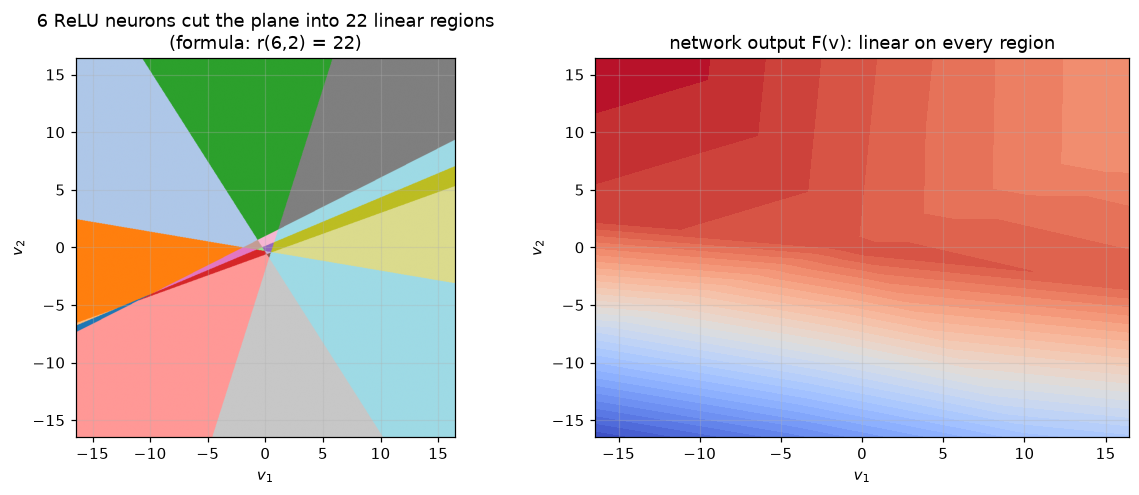

In [3]:
N = 6
_, patterns, g, W, b = count_regions_2d(N, grid=800, seed=2)
codes = patterns @ (1 << np.arange(N))
_, labels = np.unique(codes, return_inverse=True)
v_out = np.random.default_rng(5).standard_normal(N)
F = relu(np.stack(np.meshgrid(g, g), -1).reshape(-1, 2) @ W.T + b) @ v_out

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].imshow(labels.reshape(len(g), len(g)), origin="lower", extent=[g[0], g[-1], g[0], g[-1]], cmap="tab20")
axes[0].set_title(f"{N} ReLU neurons cut the plane into {labels.max() + 1} linear regions\n(formula: r(6,2) = 22)")
axes[1].contourf(g, g, F.reshape(len(g), len(g)), levels=40, cmap="coolwarm")
axes[1].set_title("network output F(v): linear on every region")
for ax in axes:
    ax.set_xlabel("$v_1$"); ax.set_ylabel("$v_2$")
plt.tight_layout()
plt.savefig(FIG / "06_relu_linear_regions.png", bbox_inches="tight")
plt.show()

## 2. Depth beats width: composition $F_3(F_2(F_1(v)))$

The "tent" map $T(x) = 2\,\mathrm{ReLU}(x) - 4\,\mathrm{ReLU}(x - \tfrac12)$ needs only **2 neurons**. On $[0,1]$ it has 2 linear pieces.
Composing it $L$ times gives $2^L$ pieces with only $2L$ neurons, while a single hidden layer needs about $2^L$ neurons for the same function.
This is the reason **deep** networks are so expressive.

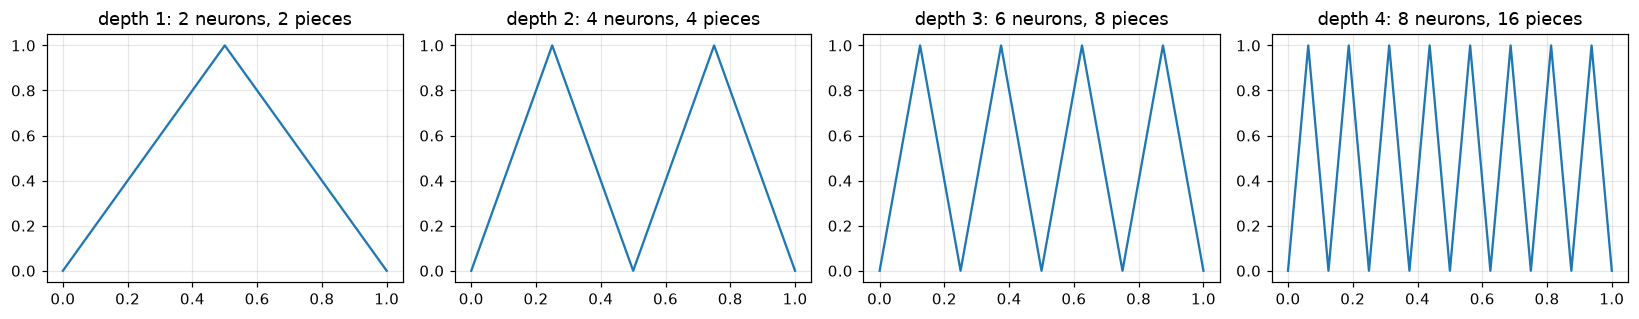

In [4]:
tent = lambda x: 2 * relu(x) - 4 * relu(x - 0.5)
x = np.linspace(0, 1, 4001)
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
y = x
for L, ax in enumerate(axes, start=1):
    y = tent(y)
    slopes = np.round(np.diff(y) / np.diff(x), 6)
    pieces = 1 + np.count_nonzero(np.diff(slopes))
    ax.plot(x, y)
    ax.set_title(f"depth {L}: {2 * L} neurons, {pieces} pieces")
plt.tight_layout()
plt.savefig(FIG / "06_depth_sawtooth.png", bbox_inches="tight")
plt.show()

## 3. A one-hidden-layer network trained with hand-written backpropagation

We fit $y = \sin(2\pi x) + 0.5\cos(5\pi x)$ on $[0, 1]$ with networks of width 2, 8 and 64, trained with full-batch ADAM on the mean squared error.
Backpropagation is just the chain rule:
$$h = \mathrm{ReLU}(xW_1 + b_1),\quad \hat y = hW_2 + b_2,\quad
\frac{\partial L}{\partial W_2} = h^T \delta,\quad \frac{\partial L}{\partial h} = \delta W_2^T,\quad
\frac{\partial L}{\partial z_1} = \frac{\partial L}{\partial h}\odot \mathbb{1}[z_1>0].$$

In [5]:
def target(x):
    return np.sin(2 * np.pi * x) + 0.5 * np.cos(5 * np.pi * x)

x_train = np.linspace(0, 1, 200)[:, None]
y_train = target(x_train)

def train_mlp(width, epochs=6000, lr=0.01, seed=0):
    r = np.random.default_rng(seed)
    # place each neuron's kink -b1/W1 inside [0, 1], so no neuron starts "dead" on the data
    W1 = r.choice([-1.0, 1.0], size=(1, width)) * r.uniform(1, 5, size=(1, width))
    params = {"W1": W1,
              "b1": -W1[0] * r.uniform(0, 1, width),
              "W2": r.standard_normal((width, 1)) * np.sqrt(2.0 / width),
              "b2": np.zeros(1)}
    m = {k: np.zeros_like(v) for k, v in params.items()}
    s = {k: np.zeros_like(v) for k, v in params.items()}
    losses = []
    for t in range(1, epochs + 1):
        z1 = x_train @ params["W1"] + params["b1"]
        h = relu(z1)
        y_hat = h @ params["W2"] + params["b2"]
        delta = 2 * (y_hat - y_train) / len(x_train)                    # dL/dy_hat
        grads = {"W2": h.T @ delta, "b2": delta.sum(0)}
        dz1 = (delta @ params["W2"].T) * (z1 > 0)
        grads["W1"] = x_train.T @ dz1
        grads["b1"] = dz1.sum(0)
        for k in params:                                                  # ADAM update
            m[k] = 0.9 * m[k] + 0.1 * grads[k]
            s[k] = 0.999 * s[k] + 0.001 * grads[k] ** 2
            params[k] -= lr * (m[k] / (1 - 0.9**t)) / (np.sqrt(s[k] / (1 - 0.999**t)) + 1e-8)
        losses.append(np.mean((y_hat - y_train) ** 2))
    predict = lambda xx: relu(xx @ params["W1"] + params["b1"]) @ params["W2"] + params["b2"]
    return predict, losses

# gradient check: compare backprop with finite differences on a tiny network
def numerical_check():
    r = np.random.default_rng(1)
    W1, b1, W2, b2 = r.standard_normal((1, 4)), r.standard_normal(4), r.standard_normal((4, 1)), r.standard_normal(1)
    L = lambda W1: np.mean((relu(x_train @ W1 + b1) @ W2 + b2 - y_train) ** 2)
    z1 = x_train @ W1 + b1
    delta = 2 * (relu(z1) @ W2 + b2 - y_train) / len(x_train)
    analytic = x_train.T @ ((delta @ W2.T) * (z1 > 0))
    eps, numeric = 1e-6, np.zeros_like(W1)
    for j in range(W1.shape[1]):
        E = np.zeros_like(W1); E[0, j] = eps
        numeric[0, j] = (L(W1 + E) - L(W1 - E)) / (2 * eps)
    return np.abs(analytic - numeric).max()

print("max |backprop - finite difference| =", f"{numerical_check():.2e}")

max |backprop - finite difference| = 1.55e-11


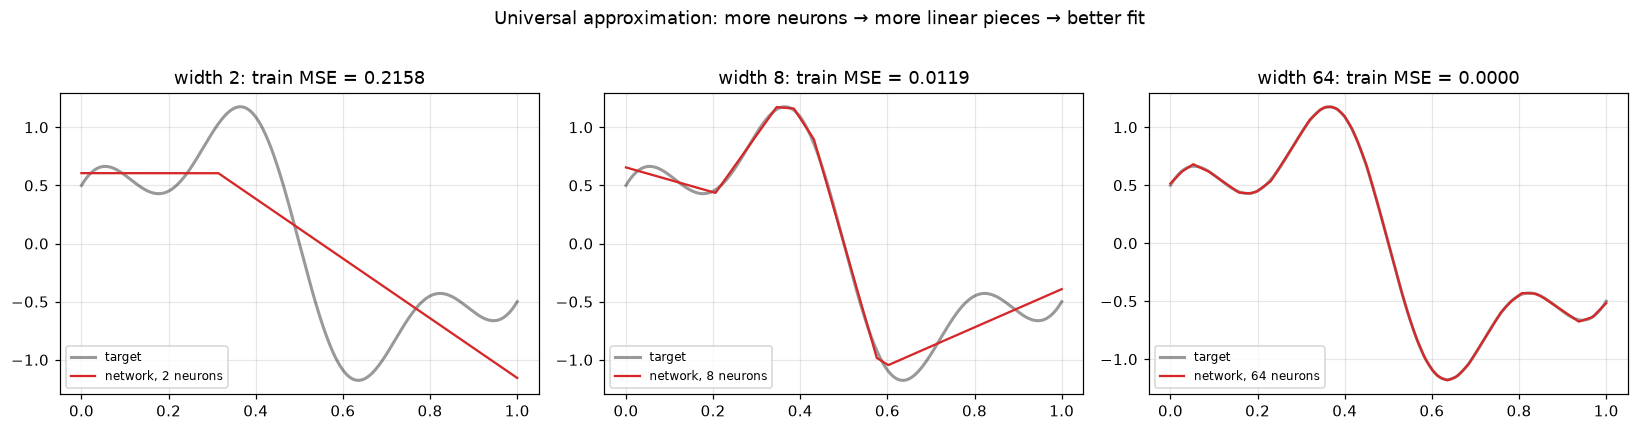

In [6]:
xx = np.linspace(0, 1, 1000)[:, None]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, width in zip(axes, [2, 8, 64]):
    predict, losses = train_mlp(width)
    ax.plot(xx, target(xx), "k", lw=2, alpha=0.4, label="target")
    ax.plot(xx, predict(xx), "tab:red", label=f"network, {width} neurons")
    ax.set_title(f"width {width}: train MSE = {losses[-1]:.4f}")
    ax.legend(fontsize=8, loc="lower left")
plt.suptitle("Universal approximation: more neurons → more linear pieces → better fit", y=1.02)
plt.tight_layout()
plt.savefig(FIG / "06_universal_approximation.png", bbox_inches="tight")
plt.show()

## 4. Bias vs variance: underfitting and overfitting

Fitting polynomials of increasing degree to 20 noisy samples: low degree **underfits** (high bias), high degree **overfits** (high variance).
The test error is U-shaped, while the training error keeps falling.

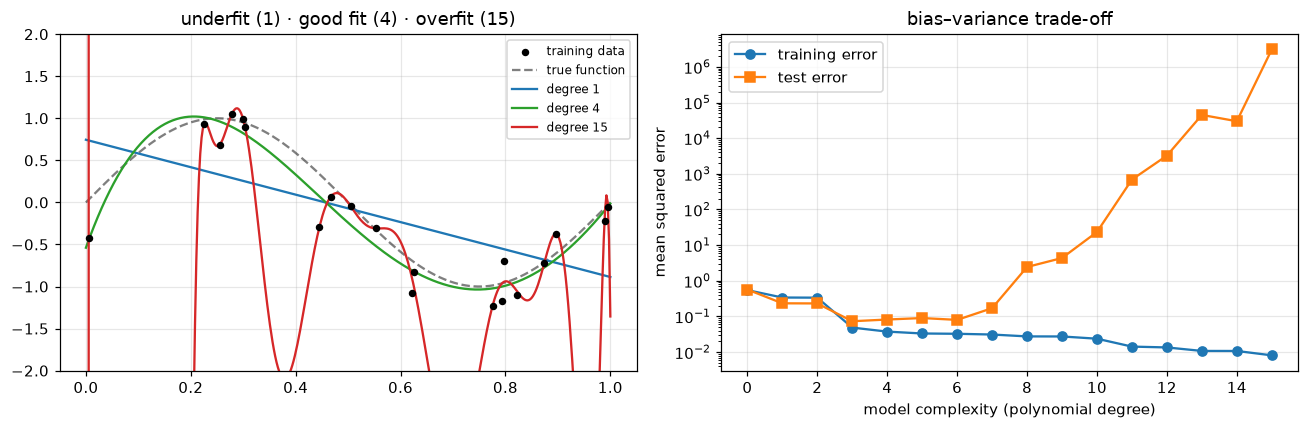

best test degree: 3


In [7]:
r = np.random.default_rng(7)
f_true = lambda x: np.sin(2 * np.pi * x)
x_tr = np.sort(r.uniform(0, 1, 20)); y_tr = f_true(x_tr) + 0.25 * r.standard_normal(20)
x_te = r.uniform(0, 1, 500);         y_te = f_true(x_te) + 0.25 * r.standard_normal(500)

degrees = range(0, 16)
train_err, test_err = [], []
for deg in degrees:
    coef = np.polynomial.legendre.legfit(2 * x_tr - 1, y_tr, deg)
    pred = lambda x: np.polynomial.legendre.legval(2 * x - 1, coef)
    train_err.append(np.mean((pred(x_tr) - y_tr) ** 2))
    test_err.append(np.mean((pred(x_te) - y_te) ** 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xs = np.linspace(0, 1, 400)
axes[0].scatter(x_tr, y_tr, c="k", s=15, zorder=3, label="training data")
axes[0].plot(xs, f_true(xs), "k--", alpha=0.5, label="true function")
for deg, col in [(1, "tab:blue"), (4, "tab:green"), (15, "tab:red")]:
    coef = np.polynomial.legendre.legfit(2 * x_tr - 1, y_tr, deg)
    axes[0].plot(xs, np.polynomial.legendre.legval(2 * xs - 1, coef), col, label=f"degree {deg}")
axes[0].set_ylim(-2, 2)
axes[0].legend(fontsize=8)
axes[0].set_title("underfit (1) · good fit (4) · overfit (15)")
axes[1].semilogy(list(degrees), train_err, "o-", label="training error")
axes[1].semilogy(list(degrees), test_err, "s-", label="test error")
axes[1].set_xlabel("model complexity (polynomial degree)")
axes[1].set_ylabel("mean squared error")
axes[1].set_title("bias–variance trade-off")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG / "06_bias_variance.png", bbox_inches="tight")
plt.show()
print("best test degree:", int(np.argmin(test_err)))

### Takeaways
* A ReLU network is a piecewise-linear function. One layer of $N$ neurons on $\mathbb{R}^2$ gives at most $1 + N + \binom N2$ pieces.
* Depth multiplies pieces (here $2^L$ from $2L$ neurons), which explains why deep networks are far more expressive than wide shallow ones.
* More capacity fits the training data better, but the test error decides. That is the bias–variance trade-off, and it motivates the regularizers (dropout, batch norm) in notebook 07.